# **Building a CNN Model for Image Classification**




# Part A: Data Understanding and Preprocessing

In [17]:
from google.colab import drive
drive.mount('/content/drive')

!ls "/content/drive/MyDrive/archive_assignm"
!unzip "/content/drive/MyDrive/archive_assignm/archive.zip" -d "/content/drive/MyDrive/archive_assignm"

Streaming output truncated to the last 5000 lines.
  inflating: /content/drive/MyDrive/archive_assignm/seg_train/seg_train/mountain/7506.jpg  
  inflating: /content/drive/MyDrive/archive_assignm/seg_train/seg_train/mountain/7537.jpg  
  inflating: /content/drive/MyDrive/archive_assignm/seg_train/seg_train/mountain/7539.jpg  
  inflating: /content/drive/MyDrive/archive_assignm/seg_train/seg_train/mountain/7551.jpg  
  inflating: /content/drive/MyDrive/archive_assignm/seg_train/seg_train/mountain/7560.jpg  
  inflating: /content/drive/MyDrive/archive_assignm/seg_train/seg_train/mountain/7565.jpg  
  inflating: /content/drive/MyDrive/archive_assignm/seg_train/seg_train/mountain/7578.jpg  
  inflating: /content/drive/MyDrive/archive_assignm/seg_train/seg_train/mountain/7581.jpg  
  inflating: /content/drive/MyDrive/archive_assignm/seg_train/seg_train/mountain/7586.jpg  
  inflating: /content/drive/MyDrive/archive_assignm/seg_train/seg_train/mountain/7647.jpg  
  inflating: /content/drive/M

In [18]:
!ls "/content/drive/MyDrive/archive_assignm"

archive.zip  seg_pred  seg_test  seg_train


In [19]:

train_dir = "/content/drive/MyDrive/archive_assignm/seg_train/seg_train"
test_dir = "/content/drive/MyDrive/archive_assignm/seg_test/seg_test"

In [20]:
import os

print(os.listdir(train_dir))
print(os.listdir(test_dir))

['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


In [21]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing import image

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import Conv2D
from tensorflow.keras.layers import MaxPooling2D
from tensorflow.keras.layers import Flatten
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout

from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.callbacks import ModelCheckpoint

from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

In [22]:
classes = os.listdir(train_dir)

print("Classes:", classes)
print("Number of Classes:", len(classes))

Classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Number of Classes: 6


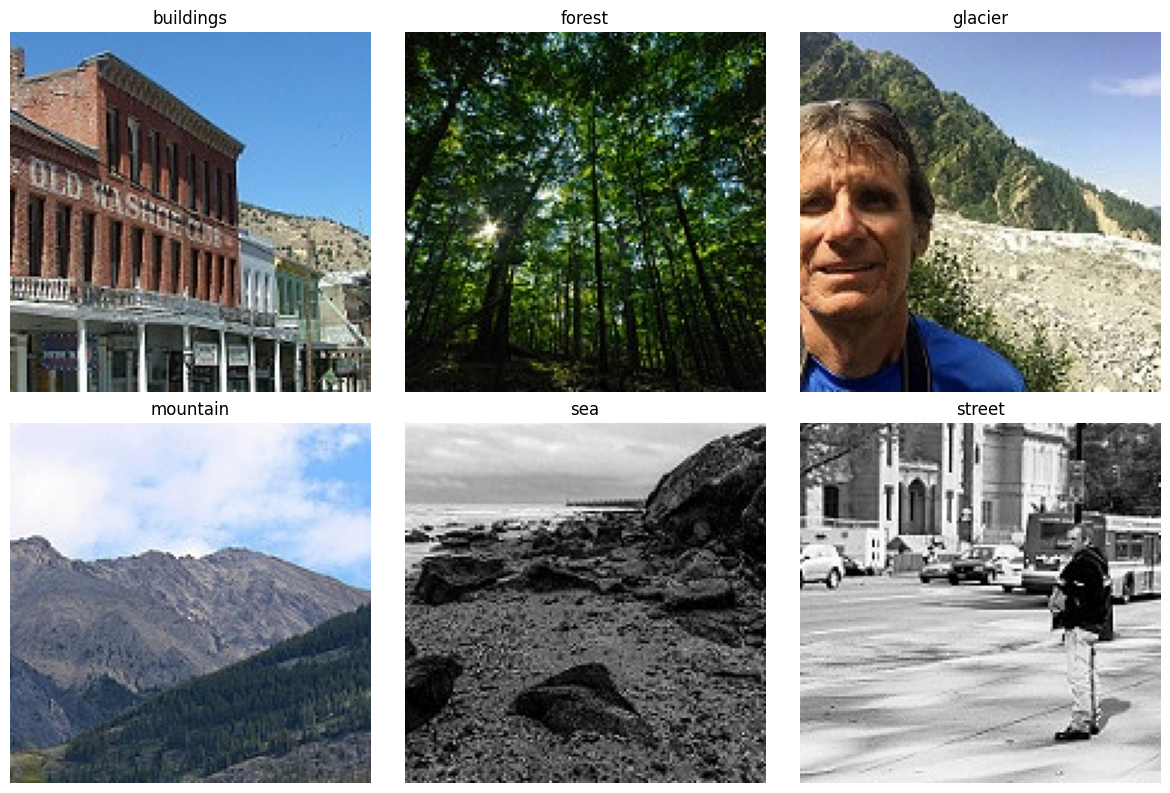

In [23]:
plt.figure(figsize=(12,8))

for i, cls in enumerate(classes):

    img_path = os.path.join(
        train_dir,
        cls,
        random.choice(os.listdir(os.path.join(train_dir, cls)))
    )

    img = image.load_img(img_path, target_size=(150,150))

    plt.subplot(2,3,i+1)
    plt.imshow(img)
    plt.title(cls)
    plt.axis('off')

plt.tight_layout()
plt.show()

In [24]:
sample_class = classes[0]

sample_image = os.path.join(
    train_dir,
    sample_class,
    os.listdir(os.path.join(train_dir, sample_class))[0]
)

img = image.load_img(sample_image)

print("Original Image Size:", img.size)

Original Image Size: (150, 150)


In [25]:
IMG_HEIGHT = 150
IMG_WIDTH = 150
BATCH_SIZE = 32

In [26]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

test_datagen = ImageDataGenerator(rescale=1./255)

In [27]:
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training'
)

Found 11230 images belonging to 6 classes.


In [28]:
validation_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation'
)

Found 2804 images belonging to 6 classes.


In [29]:
test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

Found 3000 images belonging to 6 classes.


# Part B: CNN Model Development

In [30]:
model = Sequential()

# Layer 1
model.add(Conv2D(
    32,
    (3,3),
    activation='relu',
    input_shape=(150,150,3)
))
model.add(MaxPooling2D(2,2))

# Layer 2
model.add(Conv2D(
    64,
    (3,3),
    activation='relu'
))
model.add(MaxPooling2D(2,2))

# Layer 3
model.add(Conv2D(
    128,
    (3,3),
    activation='relu'
))
model.add(MaxPooling2D(2,2))

# Layer 4
model.add(Conv2D(
    128,
    (3,3),
    activation='relu'
))
model.add(MaxPooling2D(2,2))

# Flatten
model.add(Flatten())

# Dense Layer
model.add(Dense(
    512,
    activation='relu'
))

# Dropout
model.add(Dropout(0.5))

# Output Layer
model.add(Dense(
    6,
    activation='softmax'
))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [31]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [32]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 15, 15, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     3,211,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │         3,078 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,455,686 (13.18 MB)

 Trainable params: 3,455,686 (13.18 MB)

 Non-trainable params: 0 (0.00 B)

In [33]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

In [36]:
checkpoint = ModelCheckpoint(
    'best_model.keras',
    monitor='val_accuracy',
    save_best_only=True
)

In [35]:
history = model.fit(
    train_generator,
    epochs=25,
    validation_data=validation_generator,
    callbacks=[early_stop, checkpoint]
)

Epoch 1/25
351/351 ━━━━━━━━━━━━━━━━━━━━ 1050s 3s/step - accuracy: 0.5037 - loss: 1.1987 - val_accuracy: 0.6006 - val_loss: 0.9880
Epoch 2/25
351/351 ━━━━━━━━━━━━━━━━━━━━ 885s 3s/step - accuracy: 0.6098 - loss: 0.9863 - val_accuracy: 0.6216 - val_loss: 0.9236
Epoch 3/25
351/351 ━━━━━━━━━━━━━━━━━━━━ 867s 2s/step - accuracy: 0.6557 - loss: 0.8880 - val_accuracy: 0.6837 - val_loss: 0.8360
Epoch 4/25
351/351 ━━━━━━━━━━━━━━━━━━━━ 891s 3s/step - accuracy: 0.7022 - loss: 0.7831 - val_accuracy: 0.7454 - val_loss: 0.6764
Epoch 5/25
351/351 ━━━━━━━━━━━━━━━━━━━━ 888s 3s/step - accuracy: 0.7240 - loss: 0.7411 - val_accuracy: 0.7739 - val_loss: 0.6524
Epoch 6/25
351/351 ━━━━━━━━━━━━━━━━━━━━ 870s 2s/step - accuracy: 0.7553 - loss: 0.6700 - val_accuracy: 0.7660 - val_loss: 0.6414
Epoch 7/25
351/351 ━━━━━━━━━━━━━━━━━━━━ 874s 2s/step - accuracy: 0.7641 - loss: 0.6486 - val_accuracy: 0.7639 - val_loss: 0.6492
Epoch 8/25
351/351 ━━━━━━━━━━━━━━━━━━━━ 870s 2s/step - accuracy: 0.7736 - loss: 0.6258 - val_acc

# Part C: Model Evaluation and Interpretation

In [37]:
test_loss, test_accuracy = model.evaluate(test_generator)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

94/94 ━━━━━━━━━━━━━━━━━━━━ 69s 722ms/step - accuracy: 0.8743 - loss: 0.3685
Test Loss: 0.368478387594223
Test Accuracy: 0.8743333220481873


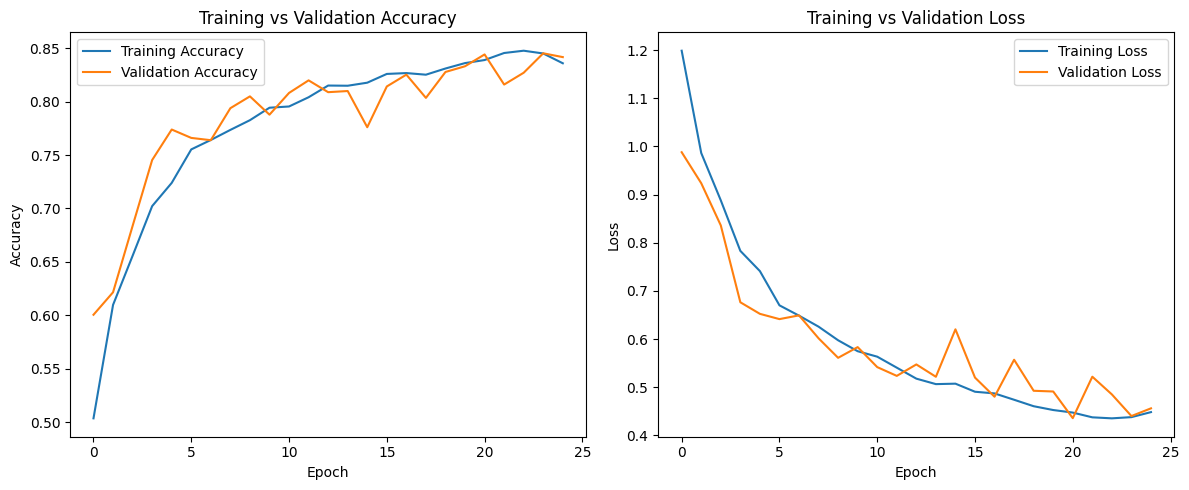

In [40]:
plt.figure(figsize=(12,5))

# Accuracy Plot
plt.subplot(1,2,1)

plt.plot(history.history['accuracy'],
         label='Training Accuracy')

plt.plot(history.history['val_accuracy'],
         label='Validation Accuracy')

plt.title('Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()


# Loss Plot
plt.subplot(1,2,2)

plt.plot(history.history['loss'],
         label='Training Loss')

plt.plot(history.history['val_loss'],
         label='Validation Loss')

plt.title('Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [39]:
predictions = model.predict(test_generator)

94/94 ━━━━━━━━━━━━━━━━━━━━ 68s 719ms/step


In [41]:
y_pred = np.argmax(predictions, axis=1)

y_true = test_generator.classes

class_names = list(test_generator.class_indices.keys())

print(class_names)

['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


In [42]:
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

              precision    recall  f1-score   support

   buildings       0.82      0.91      0.86       437
      forest       0.98      0.97      0.98       474
     glacier       0.82      0.85      0.83       553
    mountain       0.85      0.81      0.83       525
         sea       0.90      0.84      0.87       510
      street       0.89      0.88      0.89       501

    accuracy                           0.87      3000
   macro avg       0.88      0.88      0.88      3000
weighted avg       0.88      0.87      0.87      3000



In [43]:
cm = confusion_matrix(y_true, y_pred)

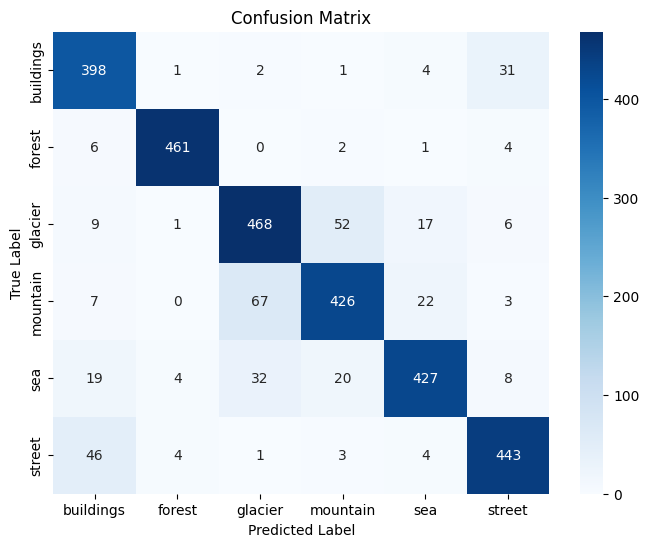

In [44]:
plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")

plt.show()

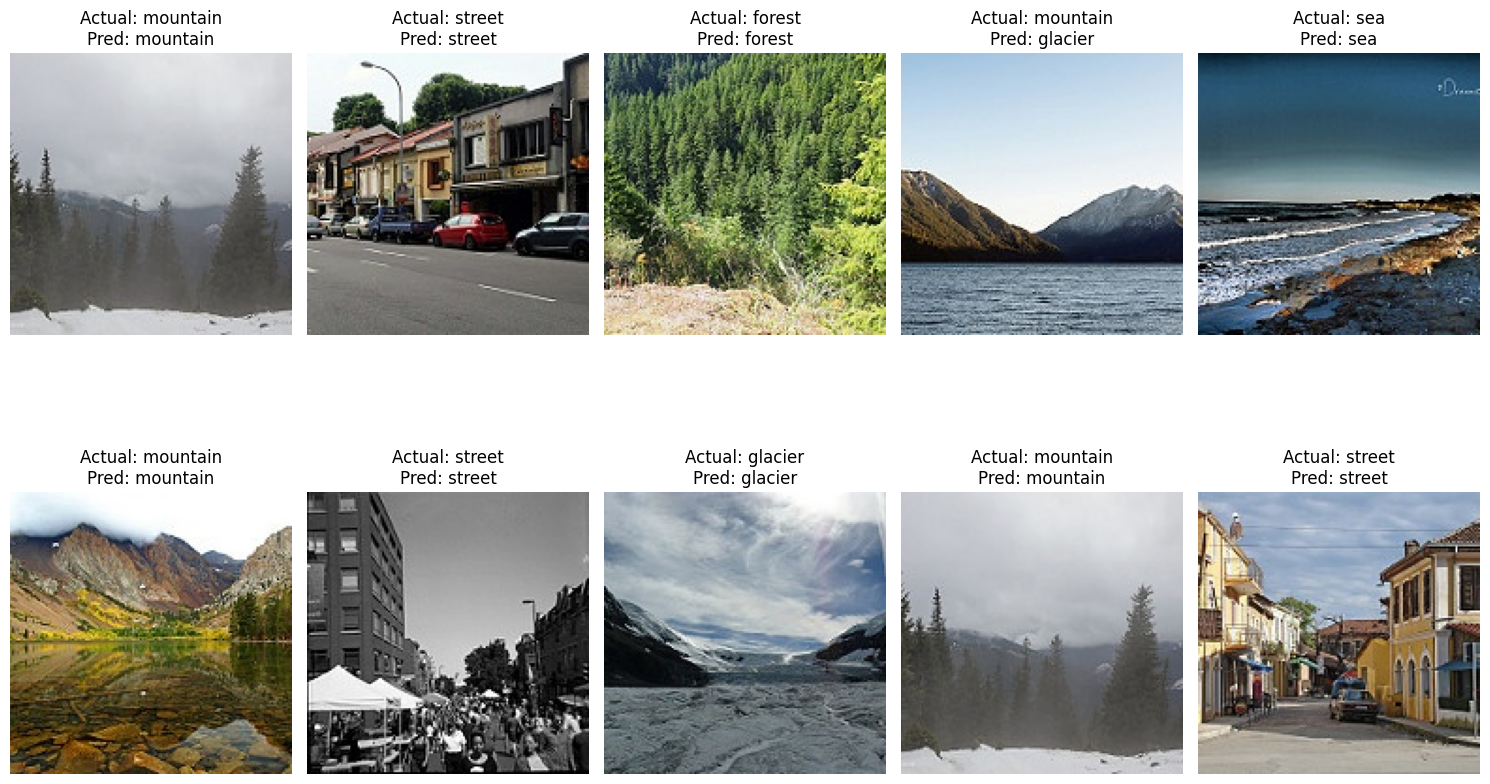

In [45]:
plt.figure(figsize=(15,10))

for i in range(10):

    index = random.randint(
        0,
        len(test_generator.filenames)-1
    )

    img_path = os.path.join(
        test_dir,
        test_generator.filenames[index]
    )

    img = image.load_img(
        img_path,
        target_size=(150,150)
    )

    img_array = image.img_to_array(img)/255.0

    img_array = np.expand_dims(
        img_array,
        axis=0
    )

    prediction = model.predict(img_array, verbose=0)

    predicted_label = class_names[
        np.argmax(prediction)
    ]

    actual_label = img_path.split('/')[-2]

    plt.subplot(2,5,i+1)

    plt.imshow(img)

    plt.title(
        f"Actual: {actual_label}\nPred: {predicted_label}"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()